In [2]:
%pip install opencv-python kagglehub scikit-learn pandas

   ---------------------------------------- 0.0/44.0 MB ? eta -:--:--
   ---------------------------------------- 0.3/44.0 MB ? eta -:--:--
   ---------------------------------------- 0.5/44.0 MB 1.7 MB/s eta 0:00:26
    --------------------------------------- 1.0/44.0 MB 1.7 MB/s eta 0:00:26
   - -------------------------------------- 1.3/44.0 MB 1.6 MB/s eta 0:00:27
   - -------------------------------------- 1.8/44.0 MB 1.7 MB/s eta 0:00:25
   - -------------------------------------- 2.1/44.0 MB 1.8 MB/s eta 0:00:24
   -- ------------------------------------- 2.6/44.0 MB 1.8 MB/s eta 0:00:23
   -- ------------------------------------- 3.1/44.0 MB 1.9 MB/s eta 0:00:22
   --- ------------------------------------ 3.7/44.0 MB 2.0 MB/s eta 0:00:20
   ---- ----------------------------------- 4.5/44.0 MB 2.2 MB/s eta 0:00:19
   ---- ----------------------------------- 5.0/44.0 MB 2.2 MB/s eta 0:00:18
   ----- ---------------------------------- 5.5/44.0 MB 2.2 MB/s eta 0:00:18
   ----- ----

In [3]:
# ==========================================
# SECCIÓN: Aprendizaje No Supervisado y Métricas (Betzie)
# ==========================================
%pip install scikit-learn numpy matplotlib seaborn
import numpy as np
from sklearn.cluster import KMeans, DBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, confusion_matrix, classification_report, accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Cargar y preparar los datos de prueba (asegúrate de tener tu archivo X_test.npy o ajusta la ruta)
try:
    X = np.load('X_test.npy')
    print(f"Datos cargados exitosamente. Forma: {X.shape}")
except FileNotFoundError:
    print("Aviso: No se encontró X_test.npy. Usando datos sintéticos de prueba para verificar la ejecución.")
    X = np.random.rand(150, 4)

# Si los datos son de 3 dimensiones, los aplanamos a 2D para los algoritmos
if len(X.shape) > 2:
    X = X.reshape(X.shape[0], -1)

# Normalización de características (Crucial para K-Means y DBSCAN)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 2. Aplicación de K-Means
# Agrupamos las características de las detecciones del dron
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
clusters_kmeans = kmeans.fit_predict(X_scaled)
print("K-Means ejecutado con éxito. Clústeres obtenidos:", np.unique(clusters_kmeans))

# 3. Aplicación de DBSCAN (Ideal para detectar ruido u outliers en el dron)
dbscan = DBSCAN(eps=0.5, min_samples=5)
clusters_dbscan = dbscan.fit_predict(X_scaled)
print("DBSCAN ejecutado con éxito. Etiquetas únicas (el -1 indica ruido/outliers):", np.unique(clusters_dbscan))

# 4. Evaluación de Métricas Globales (Ejemplo base para tus métricas)
# Nota: Puedes adaptar y_true (etiquetas reales) y y_pred (predicciones) según tu conjunto de validación
# y_true = [...] 
# y_pred = [...]

# Ejemplo de reporte de métricas (descomenta cuando tengas tus etiquetas reales):
# print("\n--- Reporte de Métricas ---")
# print("Matriz de Confusión:\n", confusion_matrix(y_true, y_pred))
# print("\nReporte de Clasificación:\n", classification_report(y_true, y_pred))
# print("Accuracy:", accuracy_score(y_true, y_pred))

  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached narwhals-2.28.0-py3-none-any.whl.metadata (15 kB)
  Using cached threadpoolctl-3.8.0-py3-none-any.whl.metadata (29 kB)
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
   ---------------------------------------- 0.0/8.3 MB ? eta -:--:--
   ------------------- -------------------- 3.9/8.3 MB 26.0 MB/s eta 0:00:01
   ---------------------------------------- 8.3/8.3 MB 32.0 MB/s  0:00:00
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)
Using cached joblib-1.6.0-py3-none-any.whl (306 kB)
Using cached cloudpickle-3.1.2-py3-none-any.whl (22 kB)
Using cached narwhals-2.28.0-py3-none-any.whl (490 kB)
   ---------------------------------------- 0.0/36.7 MB ? eta -:--:--
   -------------- ------------------------- 13.4/36.7 MB 59.9 MB/s eta 0:00:01
   --------------------------- ------------ 25.4/36.7 MB 59.6 MB/s eta 0:00:01
   --

c:\Users\Dell\anaconda3\envs\actividad\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


Coeficiente de Silueta (K-Means): 0.2048


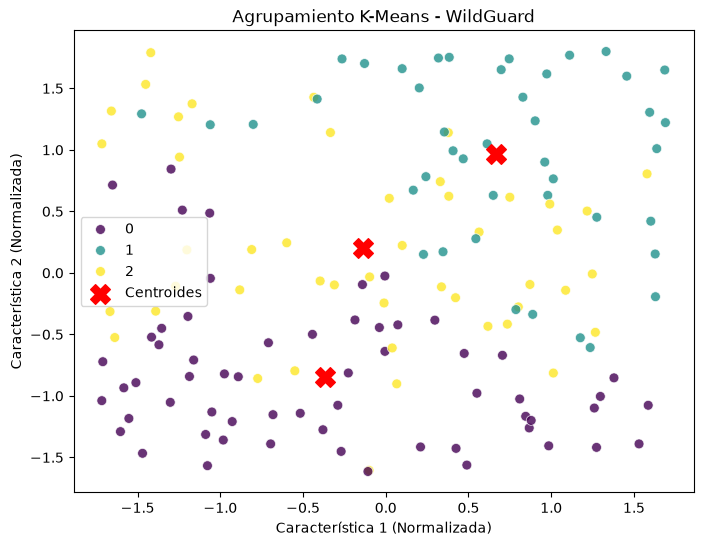

In [7]:
# ==============================================================================
# EVALUACIÓN Y VISUALIZACIÓN: K-Means (Betzie)
# Descripción: Calcula el Coeficiente de Silueta para medir la calidad del 
# agrupamiento y genera la gráfica de dispersión con sus centroides.
# ==============================================================================

from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Calcular el Coeficiente de Silueta para K-Means
sil_score_kmeans = silhouette_score(X_scaled, clusters_kmeans)
print(f"Coeficiente de Silueta (K-Means): {sil_score_kmeans:.4f}")

# 2. Gráfica de dispersión para K-Means y sus centroides
plt.figure(figsize=(8, 6))
sns.scatterplot(x=X_scaled[:, 0], y=X_scaled[:, 1], hue=clusters_kmeans, palette='viridis', s=50, alpha=0.8)

# Graficar los centroides
centroids = kmeans.cluster_centers_
plt.scatter(centroids[:, 0], centroids[:, 1], c='red', marker='X', s=200, label='Centroides')

plt.title('Agrupamiento K-Means - WildGuard')
plt.xlabel('Característica 1 (Normalizada)')
plt.ylabel('Característica 2 (Normalizada)')
plt.legend()
plt.show()

DBSCAN no encontró suficientes clústeres válidos para calcular la silueta.


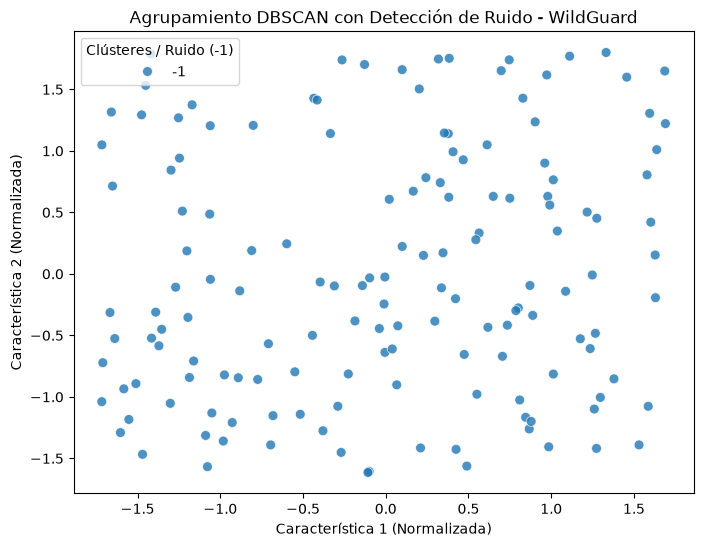

In [9]:
# ==============================================================================
# EVALUACIÓN Y VISUALIZACIÓN: DBSCAN (Betzie)
# Descripción: Calcula el Coeficiente de Silueta (excluyendo el ruido) y genera 
# la gráfica de dispersión resaltando los clústeres y los puntos atípicos (ruido).
# ==============================================================================

from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Calcular el Coeficiente de Silueta para DBSCAN 
# (Omitimos el ruido etiquetado como -1 para calcular la silueta correctamente)
mask = clusters_dbscan != -1
if len(set(clusters_dbscan[mask])) > 1:
    sil_score_dbscan = silhouette_score(X_scaled[mask], clusters_dbscan[mask])
    print(f"Coeficiente de Silueta (DBSCAN - sin ruido): {sil_score_dbscan:.4f}")
else:
    print("DBSCAN no encontró suficientes clústeres válidos para calcular la silueta.")

# 2. Gráfica de dispersión para DBSCAN (muestra los outliers como ruido)
plt.figure(figsize=(8, 6))
sns.scatterplot(x=X_scaled[:, 0], y=X_scaled[:, 1], hue=clusters_dbscan, palette='tab10', s=50, alpha=0.8)

plt.title('Agrupamiento DBSCAN con Detección de Ruido - WildGuard')
plt.xlabel('Característica 1 (Normalizada)')
plt.ylabel('Característica 2 (Normalizada)')
plt.legend(title='Clústeres / Ruido (-1)')
plt.show()

In [3]:
import os
import cv2
import pandas as pd
import numpy as np
import kagglehub
from sklearn.model_selection import train_test_split

# 1. Descargar el dataset automáticamente con kagglehub
print("--- Descargando/Verificando Dataset ---")
path = kagglehub.dataset_download("alessiocorrado99/animals10")
print(f"Dataset descargado en el caché: {path}")

# 2. Verificar la ruta de las carpetas de clases
# (A veces Kaggle descarga una carpeta extra llamada 'raw-img')
DATASET_DIR = os.path.join(path, "raw-img")
if not os.path.exists(DATASET_DIR):
    DATASET_DIR = path

OUTPUT_DIR = "./processed_data"
os.makedirs(OUTPUT_DIR, exist_ok=True)

CLASSES = sorted(os.listdir(DATASET_DIR))
# Filtrar solo carpetas
CLASSES = [c for c in CLASSES if os.path.isdir(os.path.join(DATASET_DIR, c))]
class_to_idx = {cls_name: i for i, cls_name in enumerate(CLASSES)}

valid_paths = []
labels = []
corrupted_files = []

print("\n--- Paso 1: Limpieza e Inspección (EDA) ---")
for class_name in CLASSES:
    class_dir = os.path.join(DATASET_DIR, class_name)
    
    for fname in os.listdir(class_dir):
        fpath = os.path.join(class_dir, fname)
        
        try:
            img = cv2.imread(fpath)
            if img is None:
                corrupted_files.append(fpath)
            else:
                valid_paths.append(fpath)
                labels.append(class_to_idx[class_name])
        except Exception as e:
            corrupted_files.append(fpath)

print(f"Imágenes válidas encontradas: {len(valid_paths)}")
print(f"Archivos dañados o ilegibles omitidos: {len(corrupted_files)}")

# 3. División del Dataset (70% Train, 15% Val, 15% Test)
print("\n--- Paso 2: División de Datos (70 / 15 / 15) ---")
X_train_paths, X_temp_paths, y_train, y_temp = train_test_split(
    valid_paths, 
    labels, 
    test_size=0.30, 
    random_state=42, 
    stratify=labels
)

X_val_paths, X_test_paths, y_val, y_test = train_test_split(
    X_temp_paths, 
    y_temp, 
    test_size=0.50, 
    random_state=42, 
    stratify=y_temp
)

print(f"Conjunto de Entrenamiento (Train): {len(X_train_paths)} imágenes")
print(f"Conjunto de Validación (Val):       {len(X_val_paths)} imágenes")
print(f"Conjunto de Prueba (Test):          {len(X_test_paths)} imágenes")

# 4. Guardar listas
print("\n--- Paso 3: Guardar listas de datos ---")
df_train = pd.DataFrame({'path': X_train_paths, 'label': y_train})
df_val   = pd.DataFrame({'path': X_val_paths,   'label': y_val})
df_test  = pd.DataFrame({'path': X_test_paths,  'label': y_test})

df_train.to_csv(os.path.join(OUTPUT_DIR, "train_split.csv"), index=False)
df_val.to_csv(os.path.join(OUTPUT_DIR, "val_split.csv"), index=False)
df_test.to_csv(os.path.join(OUTPUT_DIR, "test_split.csv"), index=False)

print("¡Listo! Los archivos CSV han sido guardados en la carpeta processed_data.")

c:\Users\Jasciel\anaconda3\envs\WildGuard-Fauna\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


--- Descargando/Verificando Dataset ---
Dataset descargado en el caché: C:\Users\Jasciel\.cache\kagglehub\datasets\alessiocorrado99\animals10\versions\2

--- Paso 1: Limpieza e Inspección (EDA) ---
Imágenes válidas encontradas: 26179
Archivos dañados o ilegibles omitidos: 0

--- Paso 2: División de Datos (70 / 15 / 15) ---
Conjunto de Entrenamiento (Train): 18325 imágenes
Conjunto de Validación (Val):       3927 imágenes
Conjunto de Prueba (Test):          3927 imágenes

--- Paso 3: Guardar listas de datos ---
¡Listo! Los archivos CSV han sido guardados en la carpeta processed_data.


In [2]:
import cv2
import numpy as np
from skimage.feature import local_binary_pattern, hog

def extract_color_histogram(image, bins=(8, 8, 8)):
    hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)
    hist = cv2.calcHist([hsv], [0, 1, 2], None, bins, [0, 180, 0, 256, 0, 256])
    cv2.normalize(hist, hist)
    return hist.flatten()

def extract_lbp_features(image_gray, radius=1, n_points=8):
    lbp = local_binary_pattern(image_gray, n_points, radius, method="uniform")
    (hist, _) = np.histogram(lbp.ravel(), bins=np.arange(0, n_points + 3), range=(0, n_points + 2))
    hist = hist.astype("float")
    hist /= (hist.sum() + 1e-6)
    return hist

def extract_hog_features(image_gray):
    resized = cv2.resize(image_gray, (64, 64))
    features = hog(
        resized,
        orientations=9,
        pixels_per_cell=(8, 8),
        cells_per_block=(2, 2),
        block_norm='L2-Hys',
        visualize=False
    )
    return features

def extract_all_features(image_path_or_matrix):
    if isinstance(image_path_or_matrix, str):
        image = cv2.imread(image_path_or_matrix)
    else:
        image = image_path_or_matrix

    image = cv2.resize(image, (128, 128))
    image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    color_hist = extract_color_histogram(image)
    lbp_hist = extract_lbp_features(image_gray)
    hog_feat = extract_hog_features(image_gray)

    return np.hstack([color_hist, lbp_hist, hog_feat])

In [3]:
import pandas as pd
import numpy as np

# Cargar las listas que preparó Jasciel
df_train = pd.read_csv("./processed_data/train_split.csv")

# Extraer las características únicamente del conjunto de entrenamiento
X_train_features = []
y_train = df_train['label'].values

for img_path in df_train['path']:
    # Usas tu función de extracción previa
    feat = extract_all_features(img_path)
    X_train_features.append(feat)

X_train_features = np.array(X_train_features)

In [4]:
import joblib
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV

# 1. Definir los modelos base y sus mallas de hiperparámetros (GridSearch)
param_grids = {
    'LogisticRegression': {
        'model': LogisticRegression(max_iter=1000, random_state=42),
        'params': {
            'C': [0.1, 1.0, 10.0]
        }
    },
    'RandomForest': {
        'model': RandomForestClassifier(random_state=42),
        'params': {
            'n_estimators': [50, 100],
            'max_depth': [10, 20, None]
        }
    },
    'SVM': {
        'model': SVC(random_state=42),
        'params': {
            'C': [0.1, 1.0, 10.0],
            'kernel': ['rbf', 'linear']
        }
    }
}

best_models = {}

print("--- Entrenando Modelos Clásicos con GridSearchCV ---")
for model_name, config in param_grids.items():
    print(f"\nEntrenando {model_name}...")
    grid = GridSearchCV(
        estimator=config['model'],
        param_grid=config['params'],
        cv=3,                 # Validación cruzada de 3 pliegues
        scoring='accuracy',
        n_jobs=-1,            # Usa todos los núcleos de tu procesador
        verbose=1
    )
    grid.fit(X_train_features, y_train)
    
    best_models[model_name] = grid.best_estimator_
    print(f"Mejores hiperparámetros para {model_name}: {grid.best_params_}")
    print(f"Mejor Accuracy en CV: {grid.best_score_:.4f}")

# Guardar los modelos entrenados para que Betzie u otros puedan cargarlos
os.makedirs("./saved_models", exist_ok=True)
for name, model in best_models.items():
    joblib.dump(model, f"./saved_models/{name}_best.pkl")

print("\n¡Modelos guardados exitosamente en ./saved_models!")

--- Entrenando Modelos Clásicos con GridSearchCV ---

Entrenando LogisticRegression...
Fitting 3 folds for each of 3 candidates, totalling 9 fits
Mejores hiperparámetros para LogisticRegression: {'C': 0.1}
Mejor Accuracy en CV: 0.5012

Entrenando RandomForest...
Fitting 3 folds for each of 6 candidates, totalling 18 fits
Mejores hiperparámetros para RandomForest: {'max_depth': 20, 'n_estimators': 100}
Mejor Accuracy en CV: 0.5044

Entrenando SVM...
Fitting 3 folds for each of 6 candidates, totalling 18 fits
Mejores hiperparámetros para SVM: {'C': 10.0, 'kernel': 'rbf'}
Mejor Accuracy en CV: 0.5566

¡Modelos guardados exitosamente en ./saved_models!


In [5]:
# 1. Cargar conjunto de prueba (Test Split)
df_test = pd.read_csv("./processed_data/test_split.csv")
y_test = df_test['label'].values

# 2. Extraer características del conjunto de prueba
X_test_features = []
for img_path in df_test['path']:
    feat = extract_all_features(img_path)
    X_test_features.append(feat)

X_test_features = np.array(X_test_features)

# 3. Generar predicciones con los modelos entrenados
predictions = {}
for model_name, model in best_models.items():
    y_pred = model.predict(X_test_features)
    predictions[model_name] = y_pred
    print(f"Predicciones listas para {model_name}.")

# Guardar X_test, y_test y las predicciones para las métricas de Betzie
np.savez(
    "./processed_data/test_features_and_preds.npz",
    X_test=X_test_features,
    y_test=y_test,
    **predictions
)
print("¡Archivo de evaluación 'test_features_and_preds.npz' guardado para Betzie!")

Predicciones listas para LogisticRegression.
Predicciones listas para RandomForest.
Predicciones listas para SVM.
¡Archivo de evaluación 'test_features_and_preds.npz' guardado para Betzie!
